In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.astype(int)

# Two features for 2D decision boundary visualization
X = X[:, :2]

print("Dataset Shape:", X.shape)
print("Target Distribution:\n", pd.Series(y).value_counts())

Dataset Shape: (302, 2)
Target Distribution:
 1    164
0    138
Name: count, dtype: int64


In [3]:
def split_data(X, y, test_size=0.2, seed=42):

    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []

    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)

        split = int(len(idx) * (1 - test_size))
        train_idx.extend(idx[:split])
        test_idx.extend(idx[split:])

    return (X[train_idx], X[test_idx],
            y[train_idx], y[test_idx])

X_train, X_test, y_train, y_test = split_data(X, y)

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (241, 2)
Testing: (61, 2)


In [4]:
def train_svm(X, y, C=1, lr=0.001, epochs=2000):

    labels = np.where(y == 1, 1, -1)

    weights = np.zeros(X.shape[1])
    bias = 0
    n = len(y)

    for _ in range(epochs):

        margin = labels * (X @ weights + bias)
        mask = margin < 1

        dw = weights - C * (X[mask].T @ labels[mask]) / n
        db = -C * np.sum(labels[mask]) / n

        weights -= lr * dw
        bias -= lr * db

    return weights, bias

svm_weights, svm_bias = train_svm(X_train, y_train)

def predict_svm(X, weights, bias):
    return ((X @ weights + bias) >= 0).astype(int)

svm_pred = predict_svm(X_test, svm_weights, svm_bias)

print("SVM predictions:", svm_pred[:10])

SVM predictions: [0 0 0 0 1 0 0 1 0 0]


In [5]:
def predict_knn(X_train, y_train, X_test, k=5):

    predictions = []

    for query in X_test:

        distances = np.sqrt(
            np.sum((X_train - query) ** 2, axis=1)
        )

        indices = np.argpartition(distances, k - 1)[:k]

        labels, counts = np.unique(
            y_train[indices], return_counts=True
        )

        tied = labels[counts == counts.max()]

        if len(tied) == 1:
            prediction = tied[0]
        else:
            nearest = indices[np.argmin(distances[indices])]
            prediction = y_train[nearest]

        predictions.append(prediction)

    return np.array(predictions)

knn_pred = predict_knn(X_train, y_train, X_test, k=5)

print("KNN predictions:", knn_pred[:10])

KNN predictions: [0 0 0 0 0 0 0 0 0 0]


In [6]:
def gini(y):

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def build_tree(X, y, depth=0, max_depth=5):

    classes, counts = np.unique(y, return_counts=True)
    prediction = classes[np.argmax(counts)]

    if len(classes) == 1 or depth >= max_depth or len(y) < 4:
        return prediction

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(X.shape[1]):

        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:

            left = X[:, feature] <= threshold
            right = ~left

            if not left.any() or not right.any():
                continue

            weighted = (
                left.sum() * gini(y[left]) +
                right.sum() * gini(y[right])
            ) / len(y)

            gain = gini(y) - weighted

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    if best_feature is None:
        return prediction

    left = X[:, best_feature] <= best_threshold

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_tree(X[left], y[left], depth + 1, max_depth),
        "right": build_tree(X[~left], y[~left], depth + 1, max_depth)
    }


def predict_tree(tree, row):

    while isinstance(tree, dict):

        if row[tree["feature"]] <= tree["threshold"]:
            tree = tree["left"]
        else:
            tree = tree["right"]

    return tree


tree = build_tree(X_train, y_train)

tree_pred = np.array([
    predict_tree(tree, row) for row in X_test
])

print("Decision Tree predictions:", tree_pred[:10])

Decision Tree predictions: [0 1 0 0 0 0 0 0 0 0]


In [7]:
def calculate_metrics(y_true, y_pred):

    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    return {
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100
    }


results = {
    "SVM": calculate_metrics(y_test, svm_pred),
    "KNN": calculate_metrics(y_test, knn_pred),
    "Decision Tree": calculate_metrics(y_test, tree_pred)
}

comparison = pd.DataFrame(results).T

display(comparison.round(2))

,Accuracy,Precision,Recall
SVM,77.05,75.68,84.85
KNN,63.93,86.67,39.39
Decision Tree,67.21,88.24,45.45


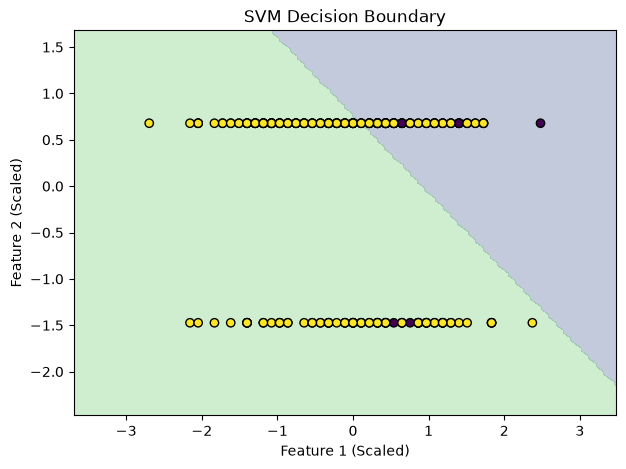

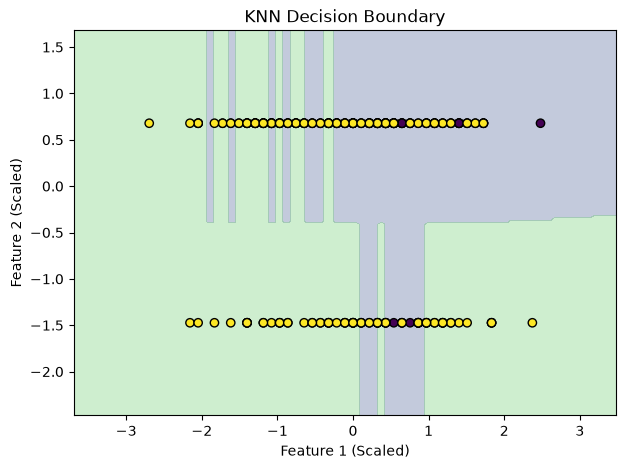

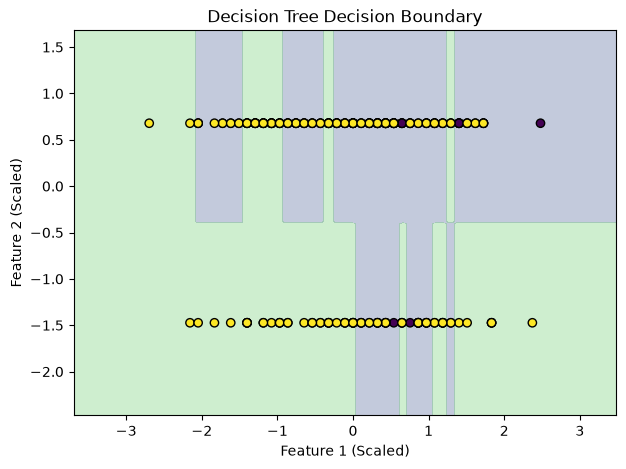

In [8]:
def plot_boundary(model, title):

    x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
    y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 150),
        np.linspace(y_min, y_max, 150)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(xx, yy, Z, alpha=0.3, levels=[-0.5, 0.5, 1.5])
    plt.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train, edgecolors="black"
    )

    plt.title(title)
    plt.xlabel("Feature 1 (Scaled)")
    plt.ylabel("Feature 2 (Scaled)")
    plt.show()


plot_boundary(
    lambda X: predict_svm(X, svm_weights, svm_bias),
    "SVM Decision Boundary"
)

plot_boundary(
    lambda X: predict_knn(X_train, y_train, X, k=5),
    "KNN Decision Boundary"
)

plot_boundary(
    lambda X: np.array([predict_tree(tree, row) for row in X]),
    "Decision Tree Decision Boundary"
)

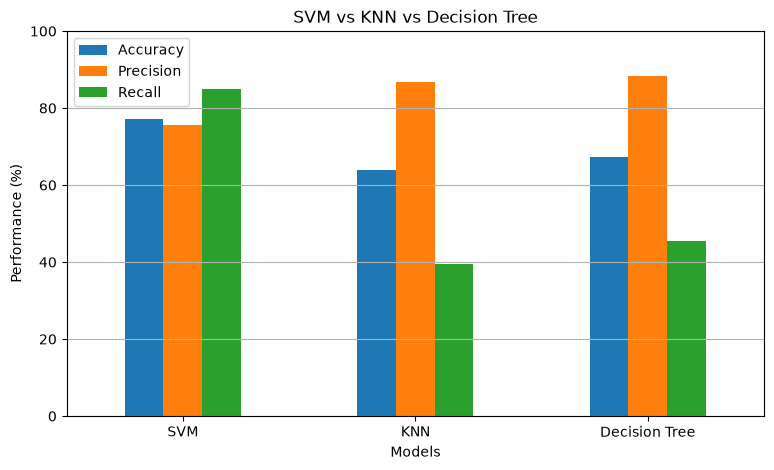

Best model by accuracy: SVM


In [9]:
comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("SVM vs KNN vs Decision Tree")
plt.ylabel("Performance (%)")
plt.xlabel("Models")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

print("Best model by accuracy:",
      comparison["Accuracy"].idxmax())

## Conclusion

In this task, SVM, KNN, and Decision Tree classifiers were
implemented from scratch and compared using the heart disease
dataset.

Accuracy, precision, and recall were manually calculated to
evaluate model performance.

Decision boundaries were visualized to understand how each
classifier separates the two classes.

SVM creates a linear decision boundary, KNN uses nearby
observations for classification, and Decision Tree creates
rule-based decision regions.

The comparison demonstrates the differences in model
behavior, performance, and practical applicability.